In [411]:
import torch
import torch.nn as nn
import torch.nn.functional as F


In [412]:
class Model(nn.Module):
    
    def __init__(self, in_features = 4, h1 = 8, h2 = 9, out_features = 3):
        # how many layers?
        super().__init__()
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)
        
          
    def forward(self, x):
        # a1 = F.relu(self.fc1(x))
        # a2 = F.relu(self.fc2(a1))
        # y = self.out(a2)
        
        # return a1, a2, y
        
        
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x) 
                
        return x         

In [413]:
torch.manual_seed(32)
model = Model()
model_extra= Model(h1 = 4, h2 = 5)
print(model.parameters, model_extra.parameters, sep='\n\n\n')

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)>


<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=4, bias=True)
  (fc2): Linear(in_features=4, out_features=5, bias=True)
  (out): Linear(in_features=5, out_features=3, bias=True)
)>


In [414]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [415]:
df = pd.read_csv('Data/iris.csv')
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0


In [416]:
df.tail()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0
149,5.9,3.0,5.1,1.8,2.0


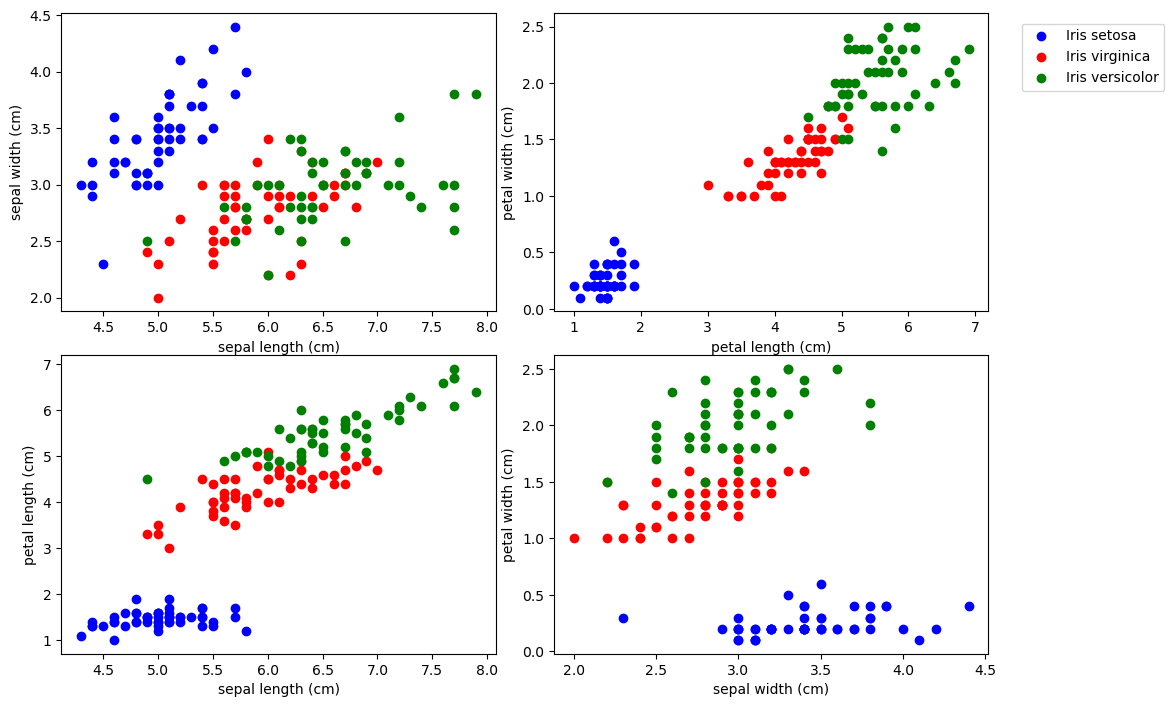

In [417]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10,7))
fig.tight_layout()

plots = [(0,1),(2,3),(0,2),(1,3)]
colors = ['b', 'r', 'g']
labels = ['Iris setosa','Iris virginica','Iris versicolor']

for i, ax in enumerate(axes.flat):
    for j in range(3):
        x = df.columns[plots[i][0]]
        y = df.columns[plots[i][1]]
        ax.scatter(df[df['target']==j][x], df[df['target']==j][y], color=colors[j])
        ax.set(xlabel=x, ylabel=y)

fig.legend(labels=labels, loc=3, bbox_to_anchor=(1.0,0.85))
plt.show()

In [418]:
X = df.drop("target", axis = 1).values
y = df['target'].values

In [419]:
from sklearn.model_selection import train_test_split as TTSplit


In [420]:
X_train, X_test, y_train, y_test = TTSplit(X, y, test_size=.2, random_state=33)

In [421]:
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape, sep='\n')

torch.Size([120, 4])
torch.Size([30, 4])
torch.Size([120])
torch.Size([30])


In [422]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.01)

criterion_extra = nn.CrossEntropyLoss()
optimizer_extra = torch.optim.Adam(model_extra.parameters(), lr = 0.01)

In [423]:
model.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)>

In [424]:
epochs = 100
losses = []

for i in range(epochs):
    
    y_pred = model(X_train)
    
    loss = criterion(y_pred, y_train)
    
    losses.append(loss.item())
    
    if i%10 ==0:
        print(f'Epoch {i+1} and loss is: {loss}')
        
    if i==(epochs-1):
        print(f'final loss in epoch {i+1} is: {loss}')
        
        
    
    # Backpropagation
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    

Epoch 1 and loss is: 1.1507114171981812
Epoch 11 and loss is: 0.9377315044403076
Epoch 21 and loss is: 0.779825747013092
Epoch 31 and loss is: 0.6099401116371155
Epoch 41 and loss is: 0.40079933404922485
Epoch 51 and loss is: 0.25436317920684814
Epoch 61 and loss is: 0.15053054690361023
Epoch 71 and loss is: 0.10086946189403534
Epoch 81 and loss is: 0.08128313720226288
Epoch 91 and loss is: 0.07231427729129791
final loss in epoch 100 is: 0.06756166368722916


In [425]:
epochs = 100
losses_extra = []

for i in range(epochs):
    
    y_pred = model_extra(X_train)
    
    loss = criterion_extra(y_pred, y_train)
    
    losses_extra.append(loss.item())
    
    if i%10 ==0:
        print(f'Epoch {i+1} and loss is: {loss}')
        
    if i==(epochs-1):
        print(f'final loss in epoch {i+1} is: {loss}')
        
        
    
    # Backpropagation
    
    optimizer_extra.zero_grad()
    loss.backward()
    optimizer_extra.step()

Epoch 1 and loss is: 1.1091545820236206
Epoch 11 and loss is: 1.0537428855895996
Epoch 21 and loss is: 0.9579924941062927
Epoch 31 and loss is: 0.8231905102729797
Epoch 41 and loss is: 0.6867939829826355
Epoch 51 and loss is: 0.5920704007148743
Epoch 61 and loss is: 0.5170756578445435
Epoch 71 and loss is: 0.44857093691825867
Epoch 81 and loss is: 0.38586562871932983
Epoch 91 and loss is: 0.33188626170158386
final loss in epoch 100 is: 0.29019996523857117


In [426]:
print(losses)
print(losses_extra)

[1.1507114171981812, 1.1166609525680542, 1.0874043703079224, 1.0641883611679077, 1.0432250499725342, 1.0236353874206543, 1.0051639080047607, 0.9889662861824036, 0.9738516211509705, 0.9566181898117065, 0.9377315044403076, 0.9184657335281372, 0.9003541469573975, 0.884484589099884, 0.8706161975860596, 0.8555073142051697, 0.8389423489570618, 0.8221998810768127, 0.8063935041427612, 0.7923727631568909, 0.779825747013092, 0.7679059505462646, 0.7558664083480835, 0.7429794669151306, 0.727937638759613, 0.7112478017807007, 0.6941067576408386, 0.6759711503982544, 0.6566075086593628, 0.6320289373397827, 0.6099401116371155, 0.5897083282470703, 0.5690031051635742, 0.5468884110450745, 0.523733377456665, 0.5002822875976562, 0.477628231048584, 0.45650026202201843, 0.4371037781238556, 0.41852954030036926, 0.40079933404922485, 0.38456210494041443, 0.369694322347641, 0.35459667444229126, 0.3389274775981903, 0.32352668046951294, 0.30919158458709717, 0.2947372794151306, 0.2804814577102661, 0.2672296762466430

Text(0.5, 0, 'epoch')

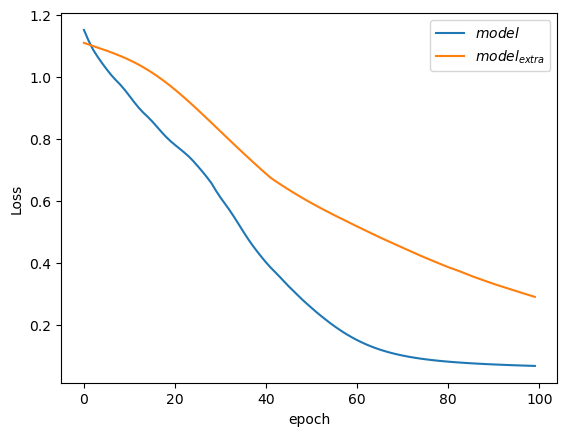

In [427]:
plt.plot(range(epochs), losses, label = '$model$')
plt.plot(range(epochs), losses_extra, label = '$model_{extra}$')
plt.legend()
plt.ylabel('Loss') 
plt.xlabel('epoch')

In [428]:
with torch.no_grad():
    y_eval = model(X_test)
    loss = criterion(y_eval, y_test)

In [429]:
loss

tensor(0.0581)

In [430]:
correct = 0

with torch.no_grad():
    for i, data in enumerate(X_test):
        y_val = model(data)
        print(f'{i+1}.) {str(y_val.argmax().item())} {y_test[i]}')
        
        if y_val.argmax().item()==y_test[i]:
            correct +=1
            
print(f'We got {correct} correct from {i+1} values')
        

1.) 1 1
2.) 1 1
3.) 0 0
4.) 1 1
5.) 2 2
6.) 2 2
7.) 0 0
8.) 0 0
9.) 2 2
10.) 2 2
11.) 2 2
12.) 0 0
13.) 2 2
14.) 1 1
15.) 2 2
16.) 1 1
17.) 2 2
18.) 0 0
19.) 1 1
20.) 2 2
21.) 0 0
22.) 0 0
23.) 2 2
24.) 0 0
25.) 2 2
26.) 2 2
27.) 1 1
28.) 1 1
29.) 2 2
30.) 2 2
We got 30 correct from 30 values


In [431]:
torch.save(model.state_dict(), 'models/basic_ann_wb.pt')
torch.save(model, 'models/basic_ann_full.pt')

In [432]:
new_model_wb = Model()
new_model_wb.load_state_dict(torch.load('models/basic_ann_wb.pt'))

<All keys matched successfully>

In [433]:
new_model_wb.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)>

In [434]:
correct = 0

with torch.no_grad():
    for i, data in enumerate(X_test):
        y_val = new_model_wb(data)
        print(f'{i+1}.) {str(y_val.argmax().item())} {y_test[i]}')
        
        if y_val.argmax().item()==y_test[i]:
            correct +=1
            
print(f'We got {correct} correct from {i+1} values')

1.) 1 1
2.) 1 1
3.) 0 0
4.) 1 1
5.) 2 2
6.) 2 2
7.) 0 0
8.) 0 0
9.) 2 2
10.) 2 2
11.) 2 2
12.) 0 0
13.) 2 2
14.) 1 1
15.) 2 2
16.) 1 1
17.) 2 2
18.) 0 0
19.) 1 1
20.) 2 2
21.) 0 0
22.) 0 0
23.) 2 2
24.) 0 0
25.) 2 2
26.) 2 2
27.) 1 1
28.) 1 1
29.) 2 2
30.) 2 2
We got 30 correct from 30 values


In [435]:
new_model = torch.load('models/basic_ann_full.pt')
new_model.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)>

In [436]:
correct = 0

with torch.no_grad():
    for i, data in enumerate(X_test):
        y_val = new_model(data)
        print(f'{i+1}.) {str(y_val.argmax().item())} {y_test[i]}')
        
        if y_val.argmax().item()==y_test[i]:
            correct +=1
            
print(f'We got {correct} correct from {i+1} values')

1.) 1 1
2.) 1 1
3.) 0 0
4.) 1 1
5.) 2 2
6.) 2 2
7.) 0 0
8.) 0 0
9.) 2 2
10.) 2 2
11.) 2 2
12.) 0 0
13.) 2 2
14.) 1 1
15.) 2 2
16.) 1 1
17.) 2 2
18.) 0 0
19.) 1 1
20.) 2 2
21.) 0 0
22.) 0 0
23.) 2 2
24.) 0 0
25.) 2 2
26.) 2 2
27.) 1 1
28.) 1 1
29.) 2 2
30.) 2 2
We got 30 correct from 30 values


In [437]:
mystery_iris = torch.tensor([5.6,3.1,4,1])

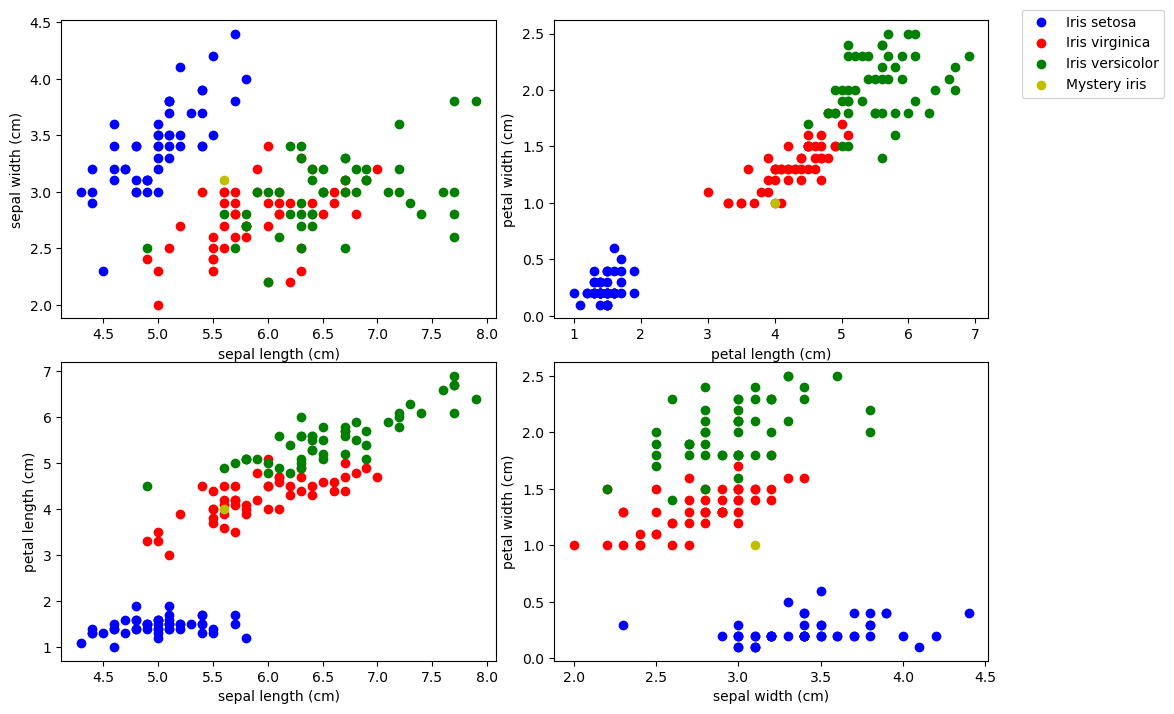

In [438]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10,7))
fig.tight_layout()

plots = [(0,1),(2,3),(0,2),(1,3)]
colors = ['b', 'r', 'g']
labels = ['Iris setosa','Iris virginica','Iris versicolor','Mystery iris']

for i, ax in enumerate(axes.flat):
    for j in range(3):
        x = df.columns[plots[i][0]]
        y = df.columns[plots[i][1]]
        ax.scatter(df[df['target']==j][x], df[df['target']==j][y], color=colors[j])
        ax.set(xlabel=x, ylabel=y)
        
    # Add a plot for our mystery iris:
    ax.scatter(mystery_iris[plots[i][0]],mystery_iris[plots[i][1]], color='y')
    
fig.legend(labels=labels, loc=3, bbox_to_anchor=(1.0,0.85))
plt.show()

In [449]:
iris_list = ['Iris setosa','Iris virginica','Iris versicolor','Mystery iris']
with torch.no_grad():
    print(iris_list[new_model(mystery_iris).argmax()])

Iris virginica


In [448]:
new_model(mystery_iris).item()

ValueError: only one element tensors can be converted to Python scalars